# MNIST handwritten digits - convolutional neural network

Study preparation. Run all cells from top to bottom. Outputs below are from a fresh Python execution, not the supplied saved outputs. Full original epoch counts and datasets are preserved. Numeric results can vary across software versions.

## Cell 1: Set up reproducibility

Set random seeds and CPU thread limits. No paid GPU is needed.

In [1]:
# Reproducible CPU-friendly setup. Colab already includes the main libraries.
import os, random
os.environ["TF_NUM_INTRAOP_THREADS"] = "2"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import numpy as np
import tensorflow as tf
random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("Execution device: CPU")


TensorFlow: 2.16.1
Execution device: CPU

## Cell 2: Import CNN tools

Conv2D learns spatial filters; MaxPooling2D downsamples; Flatten feeds the extracted features into Dense layers. SGD is the optimizer; accuracy_score independently checks predicted labels. Some original imports are unused.

In [2]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Conv2D, Dense, MaxPooling2D
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

## Cell 3: Load MNIST

Load the full 60,000/10,000 training/test split. Images are 28 x 28 and labels are integer digits.

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

## Cell 4: Check training shape

Confirm the number and dimensions of training samples before reshaping.

In [4]:
print(X_train.shape)

(60000, 28, 28)

## Cell 5: Check raw pixel range

Raw MNIST pixels are uint8 intensities between 0 and 255. This cell shows the first image range.

In [5]:
X_train[0].min(), X_train[0].max()

(0, 255)

## Cell 6: Normalize

Scale both splits into [0,1]. Apply the same preprocessing at prediction time.

In [6]:
X_train = (X_train - 0.0) / (255.0 - 0.0)
X_test = (X_test - 0.0) / (255.0 - 0.0)
X_train[0].min(), X_train[0].max()

(0.0, 1.0)

## Cell 7: View labelled training examples

Define a helper that draws an image and its label, then plot the first 20 examples in a 4 x 5 grid.

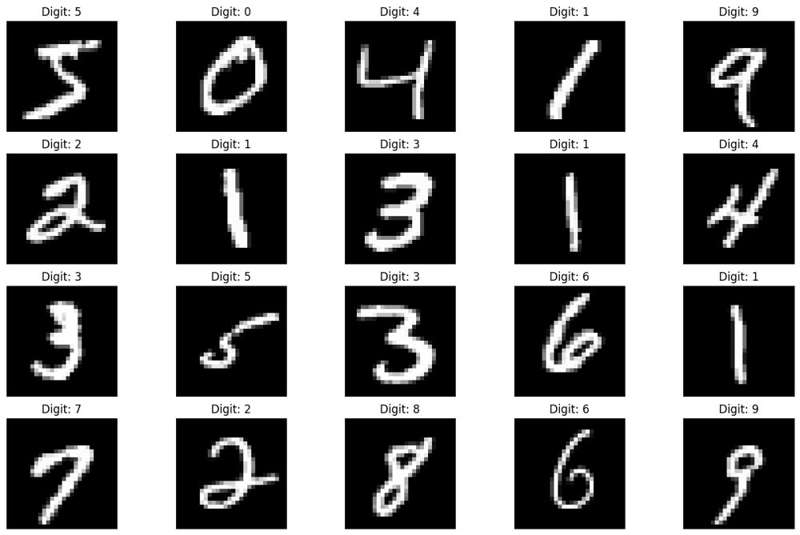

In [7]:
def plot_digit(image, digit, plt, i):
    plt.subplot(4, 5, i + 1)
    plt.imshow(image, cmap=plt.get_cmap('gray'))
    plt.title(f"Digit: {digit}")
    plt.xticks([])
    plt.yticks([])
plt.figure(figsize=(16, 10))
for i in range(20):
    plot_digit(X_train[i], y_train[i], plt, i)   
plt.show()

## Cell 8: Add the channel dimension

Conv2D expects (samples,height,width,channels). Reshape from (N,28,28) to (N,28,28,1) because these are grayscale images.

In [8]:
X_train = X_train.reshape((X_train.shape + (1,)))
X_test = X_test.reshape((X_test.shape + (1,)))

## Cell 9: Inspect labels

Show the first 20 integer labels. Sparse categorical cross-entropy accepts these directly.

In [9]:
y_train[0:20]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9],
      dtype=uint8)

## Cell 10: Build the CNN

32 filters of size 3 x 3 learn local strokes. Valid convolution gives 26 x 26 x 32; 2 x 2 pooling gives 13 x 13 x 32. Flatten makes 5408 features; Dense(100) learns combinations and softmax gives 10 class probabilities.

In [10]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(100, activation="relu"),
    Dense(10, activation="softmax")
])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)

## Cell 11: Compile and inspect parameters

SGD uses learning rate 0.01 and momentum 0.9. Momentum smooths gradient updates. Sparse categorical cross-entropy matches the integer labels. Total parameters: 542,230.

In [11]:
optimizer = SGD(learning_rate=0.01, momentum=0.9)
model.compile(
    optimizer=optimizer, 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       540,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,230 (2.07 MB)

 Trainable params: 542,230 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

## Cell 12: Train

Train on all training samples for 10 epochs, batch size 32. No validation split is used in the original CNN training cell.

In [12]:
model.fit(X_train, y_train, epochs=10, batch_size=32)

[Terminal progress animation condensed; recorded end-of-epoch results follow.]
Epoch 1: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9270 - loss: 0.2408
Epoch 2: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9770 - loss: 0.0764
Epoch 3: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9858 - loss: 0.0478
Epoch 4: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9905 - loss: 0.0336
Epoch 5: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9930 - loss: 0.0240
Epoch 6: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9956 - loss: 0.0173
Epoch 7: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9969 - loss: 0.0129
Epoch 8: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9979 - loss: 0.0092
Epoch 9: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9986 - loss: 0.0068
Epoch 10: 1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9991 - loss: 0.0049

## Cell 13: Predict random examples

Choose 20 random test images. model.predict returns probabilities; argmax returns the predicted digit. The titles in this plot are predictions, not ground-truth labels.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

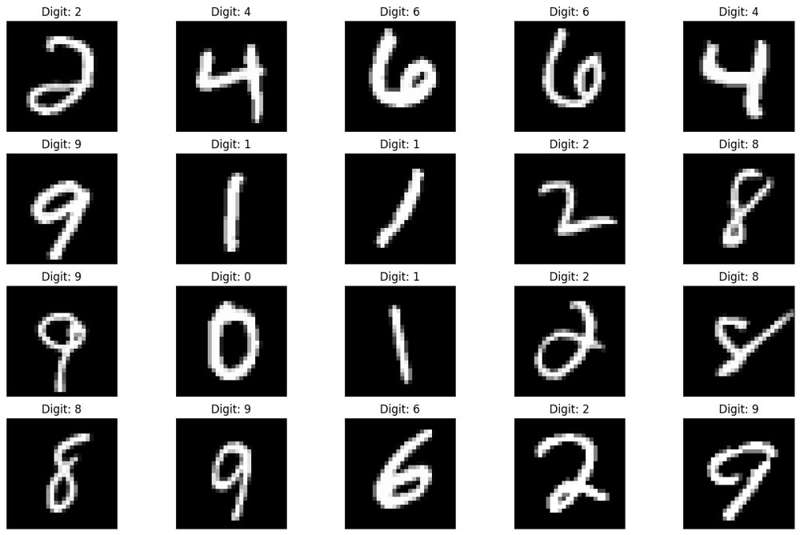

In [13]:
plt.figure(figsize=(16, 10))
for i in range(20):
    image = random.choice(X_test).squeeze()
    digit = np.argmax(model.predict(image.reshape((1, 28, 28, 1)))[0], axis=-1)
    plot_digit(image, digit, plt, i)
plt.show()

## Cell 14: Calculate test accuracy

Predict all test labels, then compare them with y_test using accuracy_score. This is the fraction correct, not the training accuracy.

In [14]:
predictions = np.argmax(model.predict(X_test), axis=-1)
accuracy_score(y_test, predictions)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step 34/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step   65/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 97/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step129/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step162/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step197/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step232/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step267/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step302/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

0.9889

## Cell 15: Show one test image

Select another test image. squeeze removes the singleton channel axis for a clear grayscale display.

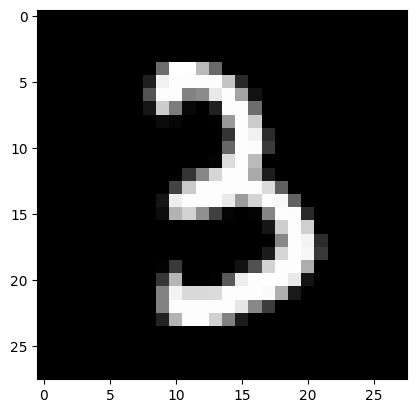

In [15]:
n=random.randint(0,9999)
plt.imshow(X_test[n].squeeze(), cmap="gray")
plt.show()

## Cell 16: Print its predicted digit

Use the softmax argmax at index n to print the digit shown above. Predicting the entire test set again is redundant but preserves the original practical flow.

In [16]:
predicted_value=model.predict(X_test)
print("Handwritten number in the image is= %d" %np.argmax(predicted_value[n]))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step 34/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  66/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step101/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step136/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step171/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step204/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step238/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step272/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step305/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Handwritten number in the image is= 3

## Cell 17: Evaluate test loss and accuracy

model.evaluate computes sparse cross-entropy and accuracy. The fresh accuracy agrees with the independent sklearn calculation. Any old numeric comments in the source are historical, not this run.

In [17]:
score = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', score[0]) #Test loss: 0.0296396646054
print('Test accuracy:', score[1])

Test loss: 0.0443047396838665
Test accuracy: 0.9889000058174133